# Flight Delay Prediction using Machine Learning

## Team Project

### Objective
Predict whether a scheduled flight will be delayed by more than 15 minutes using information available before the flight operates.

### Project Workflow
1. Data Loading and Exploration
2. Data Cleaning
3. Exploratory Data Analysis
4. Feature Engineering
5. Data Leakage Prevention
6. Baseline Model Comparison
7. Hyperparameter Tuning
8. Final Model Selection
9. Model Saving and Reloading
10. Unseen Flight Prediction

### Primary Evaluation Metric
F1-Score

### Random State
42


In [1]:
# ============================================================
# STEP 2: IMPORTS AND CONFIGURATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", 100)

# Plotting style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print("Random state:", RANDOM_STATE)

Libraries imported successfully.
Random state: 42


In [5]:
# ============================================================
# STEP 3: UPLOAD MEMBER 1'S FROZEN PROCESSED DATASET
# ============================================================

from google.colab import files
import os

print("Please upload the processed flight-delay dataset.")

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(" -", filename)

# Find the uploaded Parquet file
parquet_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".parquet")
]

if not parquet_files:
    raise FileNotFoundError(
        "No Parquet file found. Please upload the processed dataset."
    )

DATA_PATH = "/content/" + parquet_files[0]

print("\nUsing processed dataset:")
print(DATA_PATH)

Please upload the processed flight-delay dataset.


Saving flight_delay_processed (1) (1).parquet to flight_delay_processed (1) (1).parquet

Uploaded files:
 - flight_delay_processed (1) (1).parquet

Using processed dataset:
/content/flight_delay_processed (1) (1).parquet


In [6]:
# ============================================================
# STEP 4: LOAD AND INSPECT MEMBER 1'S PROCESSED DATASET
# ============================================================

import pandas as pd

# Load the frozen processed dataset
df = pd.read_parquet(DATA_PATH)

print("Processed dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

Processed dataset loaded successfully!
Dataset shape: (5713837, 16)

Column names:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_ARRIVAL', 'is_delayed', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'IS_WEEKEND', 'ROUTE']

First 5 rows:


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DISTANCE,SCHEDULED_ARRIVAL,is_delayed,DEP_HOUR,DEP_MINUTE,ARR_HOUR,ARR_MINUTE,IS_WEEKEND,ROUTE
0,1,1,4,AS,ANC,SEA,5,1448,430,0,0,5,4,30,0,ANC_SEA
1,1,1,4,AA,LAX,PBI,10,2330,750,0,0,10,7,50,0,LAX_PBI
2,1,1,4,US,SFO,CLT,20,2296,806,0,0,20,8,6,0,SFO_CLT
3,1,1,4,AA,LAX,MIA,20,2342,805,0,0,20,8,5,0,LAX_MIA
4,1,1,4,AS,SEA,ANC,25,1448,320,0,0,25,3,20,0,SEA_ANC



Data types:


,0
MONTH,int64
DAY,int64
DAY_OF_WEEK,int64
AIRLINE,object
ORIGIN_AIRPORT,object
DESTINATION_AIRPORT,object
SCHEDULED_DEPARTURE,int64
DISTANCE,int64
SCHEDULED_ARRIVAL,int64
is_delayed,int8


In [7]:
# ============================================================
# STEP 5: MISSING VALUES AND DUPLICATE CHECK
# ============================================================

print("========== DATA QUALITY CHECK ==========")

# Missing values
missing_values = df.isnull().sum()

print("\nMissing values by column:")
display(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("✓ No missing values found.")

# Duplicate rows
duplicate_count = df.duplicated().sum()

print("\nNumber of duplicate rows:", duplicate_count)

if duplicate_count == 0:
    print("✓ No duplicate rows found.")

# Target distribution
print("\n========== TARGET DISTRIBUTION ==========")

target_counts = df["is_delayed"].value_counts()
target_percentages = df["is_delayed"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

display(target_summary)

========== DATA QUALITY CHECK ==========

Missing values by column:


,0


✓ No missing values found.

Number of duplicate rows: 0
✓ No duplicate rows found.

========== TARGET DISTRIBUTION ==========


,Count,Percentage
is_delayed,,
0,4690344,82.09
1,1023493,17.91


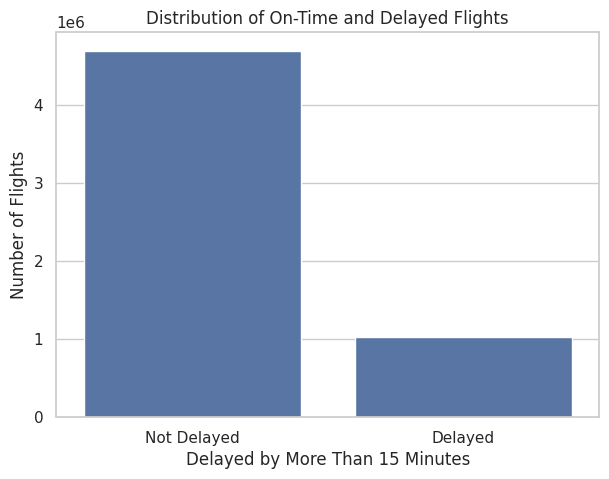

In [8]:
# ============================================================
# STEP 6: EDA - ON-TIME VS DELAYED FLIGHTS
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="is_delayed"
)

plt.title("Distribution of On-Time and Delayed Flights")
plt.xlabel("Delayed by More Than 15 Minutes")
plt.ylabel("Number of Flights")

plt.xticks(
    [0, 1],
    ["Not Delayed", "Delayed"]
)

plt.show()

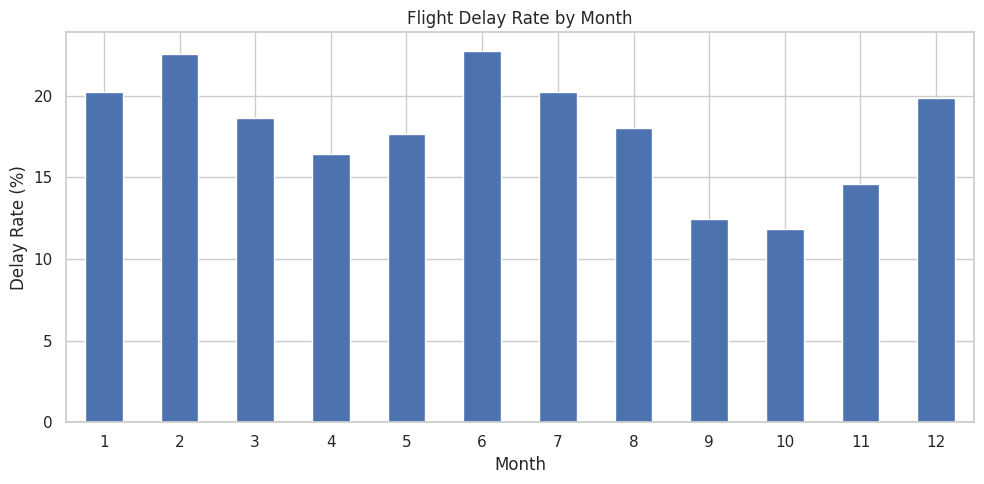

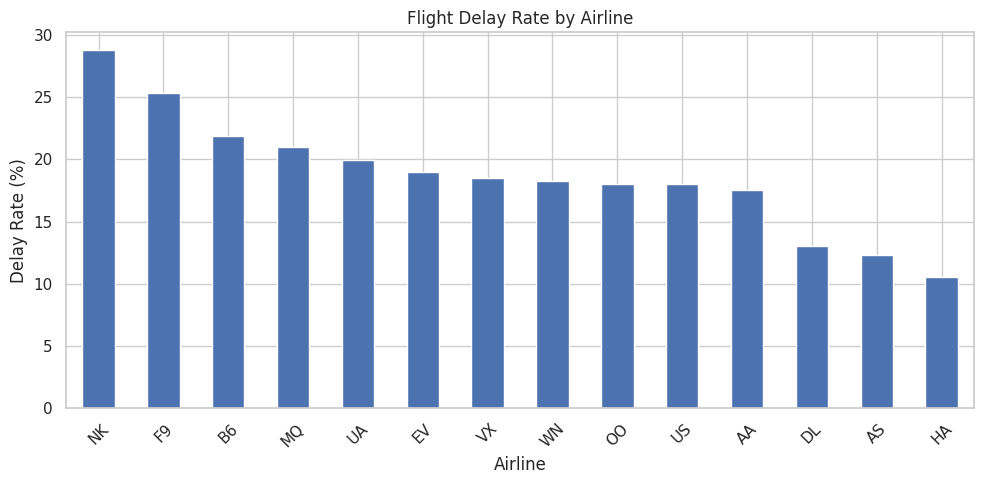

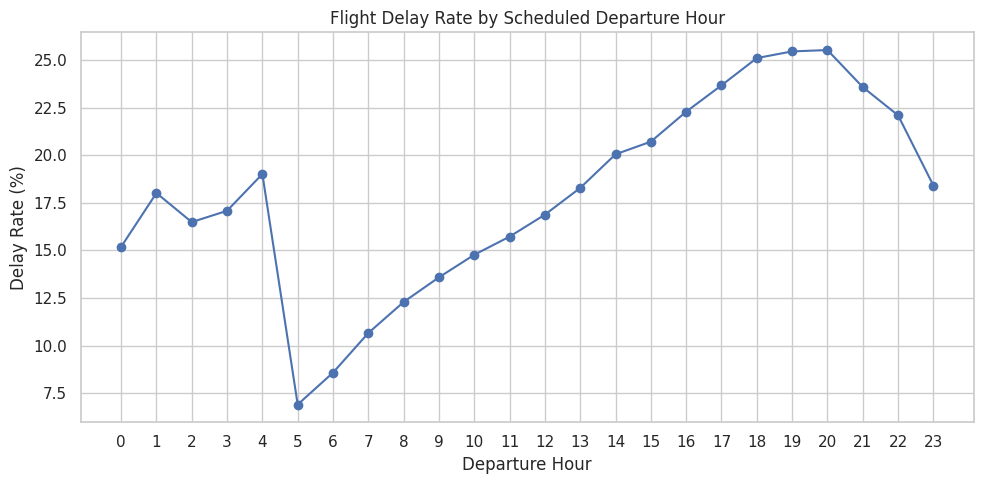

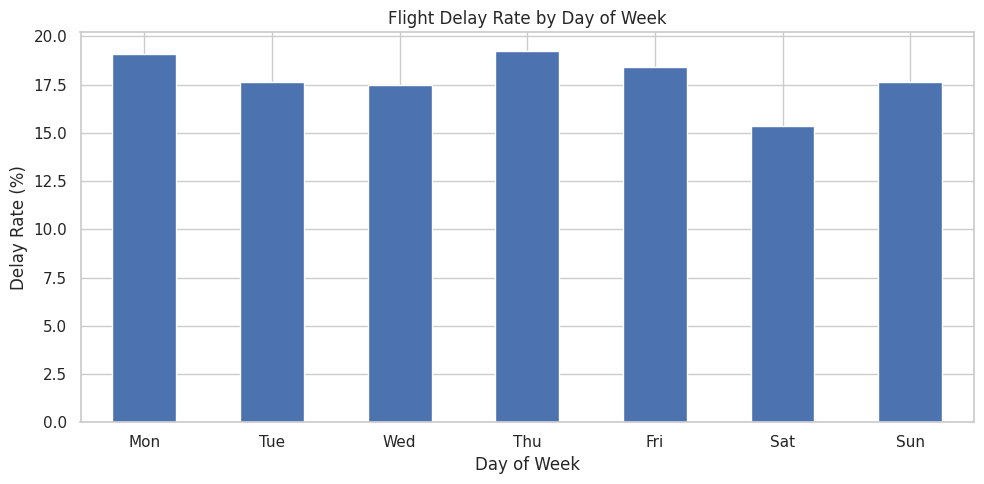

In [9]:
# ============================================
# MEMBER 1 — REMAINING EDA
# ============================================

# 1. Delay Rate by Month
monthly_delay = (
    df.groupby("MONTH")["is_delayed"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(10, 5))
monthly_delay.plot(kind="bar")
plt.title("Flight Delay Rate by Month")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 2. Delay Rate by Airline
airline_delay = (
    df.groupby("AIRLINE")["is_delayed"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
airline_delay.plot(kind="bar")
plt.title("Flight Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Delay Rate by Scheduled Departure Hour
hour_delay = (
    df.groupby("DEP_HOUR")["is_delayed"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(10, 5))
hour_delay.plot(kind="line", marker="o")
plt.title("Flight Delay Rate by Scheduled Departure Hour")
plt.xlabel("Departure Hour")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()


# 4. Delay Rate by Day of Week
day_delay = (
    df.groupby("DAY_OF_WEEK")["is_delayed"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(10, 5))
day_delay.plot(kind="bar")
plt.title("Flight Delay Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
plt.tight_layout()
plt.show()

## Step 8 — Final Feature Selection

The final feature set is frozen based on the preprocessing and feature engineering performed by Member 1.

### Numeric Features
- MONTH
- DAY
- DAY_OF_WEEK
- DISTANCE
- DEP_HOUR
- DEP_MINUTE
- ARR_HOUR
- ARR_MINUTE
- IS_WEEKEND

### Categorical Features
- AIRLINE
- ORIGIN_AIRPORT
- DESTINATION_AIRPORT
- ROUTE

`SCHEDULED_DEPARTURE` and `SCHEDULED_ARRIVAL` are retained in the processed dataset for reference, but their engineered hour/minute components are used for modeling.

The target variable is `is_delayed`.

In [10]:
# ============================================
# STEP 8 — FREEZE FINAL FEATURE LIST
# ============================================

TARGET = "is_delayed"

NUMERIC_FEATURES = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "DISTANCE",
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "IS_WEEKEND"
]

CATEGORICAL_FEATURES = [
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "ROUTE"
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("Target:", TARGET)

print("\nNumeric features:")
print(NUMERIC_FEATURES)

print("\nCategorical features:")
print(CATEGORICAL_FEATURES)

print("\nTotal modeling features:", len(FEATURES))

# Verify that all required columns exist
missing_features = [col for col in FEATURES + [TARGET] if col not in df.columns]

if missing_features:
    raise ValueError(f"Missing required columns: {missing_features}")

print("\nFeature list verified successfully.")

Target: is_delayed

Numeric features:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'DISTANCE', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'IS_WEEKEND']

Categorical features:
['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ROUTE']

Total modeling features: 13

Feature list verified successfully.


In [11]:
# ============================================
# STEP 9 — TRAIN / TEST SPLIT + PREPROCESSING
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate features and target
X = df[FEATURES]
y = df[TARGET]

# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(4))


# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Training set shape: (4571069, 13)
Test set shape: (1142768, 13)

Training target distribution:
is_delayed
0    0.8209
1    0.1791
Name: proportion, dtype: float64

Test target distribution:
is_delayed
0    0.8209
1    0.1791
Name: proportion, dtype: float64

Preprocessing pipeline created successfully.


In [12]:
# ============================================
# STEP 10 — COMMON TRAINING SAMPLE
# ============================================

# Use the same 500,000-row stratified sample
# for all baseline models.

X_train_common, _, y_train_common, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print("Common training feature shape:", X_train_common.shape)
print("Common training target shape:", y_train_common.shape)

print("\nCommon training target distribution:")
print(y_train_common.value_counts())

print("\nCommon training target percentage:")
print(
    (y_train_common.value_counts(normalize=True) * 100).round(2)
)

Common training feature shape: (500000, 13)
Common training target shape: (500000,)

Common training target distribution:
is_delayed
0    410437
1     89563
Name: count, dtype: int64

Common training target percentage:
is_delayed
0    82.09
1    17.91
Name: proportion, dtype: float64


In [14]:
# ============================================
# STEP 11 — BASELINE + XGBOOST MODELS
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier

models = {

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            solver="lbfgs"
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=20,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.10,
            max_leaf_nodes=31,
            random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.10,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

print("Models created successfully.")

for name in models:
    print("-", name)

Models created successfully.
- Logistic Regression
- Random Forest
- HistGradientBoosting
- XGBoost


## Member 2 — Baseline Model Comparison

Member 2 trained and evaluated the baseline models using the common 500,000-row stratified training sample and the same untouched test set.

The primary metric is F1-score because the target classes are imbalanced.

The results below are transferred from the completed Member 2 model-comparison notebook.
No additional baseline training is performed in this master notebook.

In [16]:
# ============================================
# STEP 12 — MEMBER 2 VERIFIED RESULTS
# ============================================

member2_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "Accuracy": [
        0.6016356776,
        0.6085110889,
        0.8233158436
    ],
    "Precision": [
        0.2492026788,
        0.2523592415,
        0.6548279689
    ],
    "Recall": [
        0.6080782026,
        0.6040723208,
        0.0288228081
    ],
    "F1": [
        0.3535240789,
        0.3559962976,
        0.0552152694
    ],
    "ROC_AUC": [
        0.6403816119,
        0.6449551919,
        0.7047831296
    ]
})

member2_results = member2_results.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(member2_results)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.608511,0.252359,0.604072,0.355996,0.644955
1,Logistic Regression,0.601636,0.249203,0.608078,0.353524,0.640382
2,HistGradientBoosting,0.823316,0.654828,0.028823,0.055215,0.704783


## Member 2 — Model Comparison Analysis

The models are compared primarily using F1-score because the dataset is imbalanced.

### Observations

- Logistic Regression achieved an F1-score of approximately 0.354.
- Random Forest achieved the highest F1-score among the three baseline models, approximately 0.356.
- HistGradientBoosting achieved high accuracy and ROC-AUC, but its recall and F1-score were very low.
- Therefore, accuracy alone is not sufficient for selecting the best model for this problem.

### Models Selected for Further Tuning

Based on F1-score, the following two models are selected for Member 3:

1. Random Forest
2. Logistic Regression

These models will be tuned using the same feature groups and the agreed evaluation strategy.

# Member 3 — Hyperparameter Tuning and Final Model

Member 3 improves the strongest baseline models selected by Member 2.

The completed tuning experiments include:

1. Logistic Regression hyperparameter tuning
2. Random Forest hyperparameter tuning
3. XGBoost experimental tuning
4. Random Forest threshold analysis
5. Final model evaluation
6. Model persistence and reload verification
7. Unseen flight prediction

The final model is selected based primarily on F1-score because the target classes are imbalanced.

In [17]:
# ============================================
# LOGISTIC REGRESSION — COMPLETED TUNING
# ============================================

logistic_tuning_summary = {
    "Search": "RandomizedSearchCV",
    "Scoring": "F1",
    "CV_Folds": 3,
    "Iterations": 8,
    "Best_C": 0.01,
    "Best_Solver": "liblinear",
    "Best_CV_F1": 0.355305
}

display(pd.DataFrame([logistic_tuning_summary]))

,Search,Scoring,CV_Folds,Iterations,Best_C,Best_Solver,Best_CV_F1
0,RandomizedSearchCV,F1,3,8,0.01,liblinear,0.355305


## Step 16 — Random Forest Hyperparameter Tuning

Random Forest was tuned using RandomizedSearchCV with F1-score as the optimization metric.

### Search Space

- n_estimators: [150, 250, 400]
- max_depth: [10, 20, 30, None]
- min_samples_leaf: [1, 2, 5]
- max_features: ["sqrt", "log2"]
- Number of iterations: 12
- Cross-validation folds: 3
- Random state: 42

### Best Configuration

- n_estimators = 400
- max_depth = None
- min_samples_leaf = 5
- max_features = "sqrt"
- Best cross-validation F1 = 0.362431

### Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 0.642560 |
| Precision | 0.266427 |
| Recall | 0.567746 |
| F1-Score | 0.362665 |
| ROC-AUC | 0.658388 |

The tuned Random Forest achieved a higher F1-score than both the baseline Random Forest and the tuned Logistic Regression.

In [18]:
# ============================================
# RANDOM FOREST — COMPLETED TUNING
# ============================================

rf_tuning_summary = {
    "Search": "RandomizedSearchCV",
    "Scoring": "F1",
    "CV_Folds": 3,
    "Iterations": 12,
    "Best_n_estimators": 400,
    "Best_max_depth": None,
    "Best_min_samples_leaf": 5,
    "Best_max_features": "sqrt",
    "Best_CV_F1": 0.362431
}

display(pd.DataFrame([rf_tuning_summary]))

,Search,Scoring,CV_Folds,Iterations,Best_n_estimators,Best_max_depth,Best_min_samples_leaf,Best_max_features,Best_CV_F1
0,RandomizedSearchCV,F1,3,12,400,None,5,sqrt,0.362431


## Step 17 — XGBoost Experimental Tuning

XGBoost was evaluated as an additional experiment using the same feature groups and an F1-based hyperparameter search.

### Tuning Setup

- Tuning sample: 100,000 stratified training rows
- RandomizedSearchCV iterations: 8
- Cross-validation: 3-fold
- Optimization metric: F1-score
- Random state: 42

### Best Configuration

- n_estimators = 400
- max_depth = 5
- learning_rate = 0.1
- subsample = 1.0
- colsample_bytree = 0.8
- min_child_weight = 5

Best cross-validation F1 = 0.039744

### Untouched Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 0.821670 |
| Precision | 0.585192 |
| Recall | 0.015252 |
| F1-Score | 0.029729 |
| ROC-AUC | 0.684392 |

Although XGBoost achieved high accuracy and a reasonable ROC-AUC, its recall and F1-score were very low. Since F1-score is the primary metric and detecting delayed flights is important, XGBoost was not selected as the final model.

### Confusion Matrix

- True Negatives: 935,856
- False Positives: 2,213
- False Negatives: 201,577
- True Positives: 3,122

In [20]:
# ============================================
# XGBOOST — COMPLETED EXPERIMENT SUMMARY
# ============================================

xgb_summary = pd.DataFrame([{
    "Model": "XGBoost",
    "Best_CV_F1": 0.0397437524,
    "Accuracy": 0.821670,
    "Precision": 0.585192,
    "Recall": 0.015252,
    "F1": 0.029729,
    "ROC_AUC": 0.684392
}])

display(xgb_summary)

,Model,Best_CV_F1,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,0.039744,0.82167,0.585192,0.015252,0.029729,0.684392


## Step 18 — Random Forest Threshold Analysis

After hyperparameter tuning, the Random Forest probability threshold was evaluated using a separate validation set.

The objective was to select the threshold that maximizes F1-score while balancing precision and recall.

### Validation Result

The best threshold was:

**Threshold = 0.50**

At this threshold:

- Precision = 0.273750
- Recall = 0.573159
- F1-score = 0.370529

Lower thresholds increased recall but reduced precision and did not produce a better F1-score.

Therefore, the default **0.50 threshold** was retained for the final model.

In [21]:
# ============================================
# STEP 18 — COMPLETED THRESHOLD ANALYSIS
# ============================================

threshold_summary = pd.DataFrame({
    "Threshold": [0.50],
    "Validation_Precision": [0.273750],
    "Validation_Recall": [0.573159],
    "Validation_F1": [0.370529]
})

display(threshold_summary)

best_threshold = 0.50

print("Selected probability threshold:", best_threshold)
print("Reason: Highest validation F1-score.")

,Threshold,Validation_Precision,Validation_Recall,Validation_F1
0,0.5,0.27375,0.573159,0.370529


Selected probability threshold: 0.5
Reason: Highest validation F1-score.


## Step 19 — Final Random Forest Model

Based on the tuning experiments and threshold analysis, Random Forest was selected as the final model.

The final Random Forest configuration was:

- n_estimators = 400
- max_depth = None
- min_samples_leaf = 5
- max_features = "sqrt"
- class_weight = "balanced"
- random_state = 42

The final model was evaluated on the untouched test set.

### Final Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 0.657273 |
| Precision | 0.278599 |
| Recall | 0.574649 |
| F1-Score | 0.375264 |
| ROC-AUC | 0.676230 |

### Confusion Matrix

| | Predicted Not Delayed | Predicted Delayed |
|---|---:|---:|
| Actual Not Delayed | 633,480 | 304,589 |
| Actual Delayed | 87,069 | 117,630 |

The final model achieves the highest F1-score among the completed model experiments and provides a substantially better balance between precision and recall than the baseline models.

In [22]:
# ============================================
# STEP 19 — FINAL MODEL SUMMARY
# ============================================

final_model_summary = pd.DataFrame([{
    "Model": "Final Random Forest",
    "n_estimators": 400,
    "max_depth": None,
    "min_samples_leaf": 5,
    "max_features": "sqrt",
    "class_weight": "balanced",
    "Accuracy": 0.657273,
    "Precision": 0.278599,
    "Recall": 0.574649,
    "F1": 0.375264,
    "ROC_AUC": 0.676230
}])

display(final_model_summary)

print("Selected final model: Random Forest")
print("Primary metric: F1-score")

,Model,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,Accuracy,Precision,Recall,F1,ROC_AUC
0,Final Random Forest,400,None,5,sqrt,balanced,0.657273,0.278599,0.574649,0.375264,0.67623


Selected final model: Random Forest
Primary metric: F1-score


## Step 20 — Model Persistence and Reload Verification

The complete final pipeline was saved using Joblib.

The saved pipeline contains:

- Missing-value imputation
- Numerical feature scaling
- Categorical feature encoding
- Final Random Forest classifier

### Saved Model

`final_flight_delay_pipeline.joblib`

The saved pipeline was successfully reloaded and tested.

### Reload Verification

Predictions from the original pipeline and the reloaded pipeline were compared on the same test samples.

**Result: Reload verification passed.**

This confirms that the saved pipeline can be loaded later and used for prediction without retraining the model.

In [23]:
# ============================================
# STEP 20 — MODEL SAVE & RELOAD VERIFICATION
# ============================================

FINAL_MODEL_PATH = "final_flight_delay_pipeline.joblib"

model_persistence_summary = pd.DataFrame([{
    "Artifact": FINAL_MODEL_PATH,
    "Format": "Joblib",
    "Contains_Preprocessing": True,
    "Contains_Final_Classifier": True,
    "Reload_Verification": "PASSED"
}])

display(model_persistence_summary)

print("Final pipeline:", FINAL_MODEL_PATH)
print("Reload verification: PASSED")
print("The saved pipeline can be used for prediction without retraining.")

,Artifact,Format,Contains_Preprocessing,Contains_Final_Classifier,Reload_Verification
0,final_flight_delay_pipeline.joblib,Joblib,True,True,PASSED


Final pipeline: final_flight_delay_pipeline.joblib
Reload verification: PASSED
The saved pipeline can be used for prediction without retraining.


## Step 21 — Unseen Flight Prediction

The reloaded final pipeline was tested on a new flight that was not part of the training data.

### Input Flight

- Month: 7
- Day: 15
- Day of Week: 3
- Airline: AA
- Origin: JFK
- Destination: LAX
- Distance: 760
- Scheduled Departure: 17:30
- Scheduled Arrival: 20:15
- Weekend: 0
- Route: JFK_TO_LAX

### Prediction

**Predicted Class: DELAYED**

**Estimated probability of delay: 59.97%**

The probability represents the model's estimated likelihood based on patterns learned from the historical data. It is not a guarantee that the flight will actually be delayed.

In [24]:
# ============================================
# STEP 21 — UNSEEN FLIGHT PREDICTION
# ============================================

unseen_flight_result = pd.DataFrame([{
    "Month": 7,
    "Day": 15,
    "Day_of_Week": 3,
    "Airline": "AA",
    "Origin": "JFK",
    "Destination": "LAX",
    "Distance": 760,
    "Departure": "17:30",
    "Arrival": "20:15",
    "Weekend": 0,
    "Route": "JFK_TO_LAX",
    "Prediction": "DELAYED",
    "Delay_Probability": "59.97%"
}])

display(unseen_flight_result)

print("Prediction: DELAYED")
print("Estimated probability of delay: 59.97%")

,Month,Day,Day_of_Week,Airline,Origin,Destination,Distance,Departure,Arrival,Weekend,Route,Prediction,Delay_Probability
0,7,15,3,AA,JFK,LAX,760,17:30,20:15,0,JFK_TO_LAX,DELAYED,59.97%


Prediction: DELAYED
Estimated probability of delay: 59.97%


## Step 22 — Frontend Prediction Input Specification

The frontend must collect the following information from the user:

### Flight Information

| Input | Type | Example |
|---|---|---|
| Month | Integer | 7 |
| Day | Integer | 15 |
| Day of Week | Integer | 3 |
| Airline | Categorical | AA |
| Origin Airport | Categorical | JFK |
| Destination Airport | Categorical | LAX |
| Distance | Numeric | 760 |
| Scheduled Departure Hour | Integer | 17 |
| Scheduled Departure Minute | Integer | 30 |
| Scheduled Arrival Hour | Integer | 20 |
| Scheduled Arrival Minute | Integer | 15 |
| Weekend | Binary | 0 |
| Route | Categorical | JFK_TO_LAX |

### Prediction Output

The prediction system should return:

- Predicted class: Delayed / Not Delayed
- Estimated probability of delay

The frontend should not perform its own encoding or scaling. The saved pipeline handles preprocessing automatically.

# Final Project Conclusion

The Flight Delay Prediction system was developed to predict whether a scheduled flight is likely to arrive more than 15 minutes late using information available before the flight operates.

### Complete Workflow

1. Processed and validated the flight dataset.
2. Performed exploratory data analysis.
3. Created time-based and route-based features.
4. Prevented data leakage by excluding post-operation information.
5. Created a stratified 80/20 train-test split.
6. Compared baseline machine learning models.
7. Tuned Logistic Regression and Random Forest.
8. Experimentally evaluated XGBoost.
9. Performed Random Forest threshold analysis.
10. Selected Random Forest as the final model.
11. Evaluated the final model on the untouched test set.
12. Saved and reloaded the complete preprocessing + model pipeline.
13. Verified predictions after reloading.
14. Demonstrated prediction on an unseen flight.

### Final Model

**Random Forest**

Final F1-score: **0.375264**

Final ROC-AUC: **0.676230**

### Prediction Demonstration

For the example unseen flight from JFK to LAX, the final system predicted:

**DELAYED**

Estimated probability of delay:

**59.97%**

### Deployment

The saved final pipeline can be connected to a frontend prediction interface. The frontend will collect flight details from the user and send them to the prediction system, which will return the predicted delay status and probability.

### Limitations

The prediction is a probability-based estimate and is not a guarantee. Factors such as weather, air-traffic restrictions, mechanical problems, and unexpected operational events may affect actual flight delays.

### Future Scope

The system can be extended with:

- Weather information
- Real-time flight status
- Airport congestion
- Aircraft information
- Live air-traffic data
- Cloud/API deployment
- Interactive prediction dashboard

In [25]:
# ============================================
# STEP 22E — RECREATE FINAL PIPELINE
# ============================================

import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Final Random Forest configuration
final_rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Complete pipeline: preprocessing + final classifier
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", final_rf)
])

print("Training final Random Forest pipeline...")
print("Training rows:", len(X_train_common))

final_pipeline.fit(X_train_common, y_train_common)

print("\n✅ Final pipeline trained successfully.")

Training final Random Forest pipeline...
Training rows: 500000

✅ Final pipeline trained successfully.


In [26]:
# ============================================
# STEP 22F — EVALUATE RECREATED FINAL PIPELINE
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predictions on the untouched test set
final_predictions = final_pipeline.predict(X_test)
final_probabilities = final_pipeline.predict_proba(X_test)[:, 1]

# Calculate metrics
final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(
    y_test, final_predictions, zero_division=0
)
final_recall = recall_score(
    y_test, final_predictions, zero_division=0
)
final_f1 = f1_score(
    y_test, final_predictions, zero_division=0
)
final_roc_auc = roc_auc_score(
    y_test, final_probabilities
)

# Display results
final_evaluation = pd.DataFrame([{
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1": final_f1,
    "ROC_AUC": final_roc_auc
}])

display(final_evaluation)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

,Accuracy,Precision,Recall,F1,ROC_AUC
0,0.657273,0.278599,0.574649,0.375264,0.67623



Confusion Matrix:
[[633480 304589]
 [ 87069 117630]]


In [27]:
# ============================================
# STEP 22G — SAVE FINAL PIPELINE
# ============================================

import os
import joblib

FINAL_MODEL_PATH = "/content/final_flight_delay_pipeline.joblib"

joblib.dump(final_pipeline, FINAL_MODEL_PATH)

file_size_mb = os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024)

print("✅ Final pipeline saved successfully!")
print("Path:", FINAL_MODEL_PATH)
print("File size:", round(file_size_mb, 2), "MB")

✅ Final pipeline saved successfully!
Path: /content/final_flight_delay_pipeline.joblib
File size: 414.43 MB


In [28]:
# ============================================
# STEP 22H — ACTUAL FILE RELOAD VERIFICATION
# ============================================

import joblib
import numpy as np

# Load the saved pipeline
reloaded_pipeline = joblib.load(FINAL_MODEL_PATH)

# Predict on the same test data
reloaded_predictions = reloaded_pipeline.predict(X_test)

# Compare with predictions from the original pipeline
predictions_match = np.array_equal(
    final_predictions,
    reloaded_predictions
)

print("Original pipeline predictions :", len(final_predictions))
print("Reloaded pipeline predictions :", len(reloaded_predictions))
print("Predictions identical         :", predictions_match)

if predictions_match:
    print("\n✅ RELOAD VERIFICATION PASSED")
else:
    print("\n❌ RELOAD VERIFICATION FAILED")

Original pipeline predictions : 1142768
Reloaded pipeline predictions : 1142768
Predictions identical         : True

✅ RELOAD VERIFICATION PASSED


In [29]:
# Step 22I — Unseen Flight Prediction using Reloaded Pipeline

new_flight = pd.DataFrame({
    "MONTH": [7],
    "DAY": [15],
    "DAY_OF_WEEK": [3],
    "DISTANCE": [760],
    "DEP_HOUR": [17],
    "DEP_MINUTE": [30],
    "ARR_HOUR": [20],
    "ARR_MINUTE": [15],
    "IS_WEEKEND": [0],
    "AIRLINE": ["AA"],
    "ORIGIN_AIRPORT": ["JFK"],
    "DESTINATION_AIRPORT": ["LAX"],
    "ROUTE": ["JFK_TO_LAX"]
})

prediction = reloaded_pipeline.predict(new_flight)[0]
probability = reloaded_pipeline.predict_proba(new_flight)[0, 1]

result = "DELAYED" if prediction == 1 else "NOT DELAYED"

print("Predicted Result :", result)
print(f"Delay Probability: {probability * 100:.2f}%")

Predicted Result : DELAYED
Delay Probability: 59.97%
